# Bonus — Natural-Language Q&A for the Museum Guide

Zero-shot retrieval over **1,500 WikiArt paintings** using **MiniLM-L6-v2**
(HuggingFace) and a **two-stage guardrail** that rejects out-of-scope
requests before they reach the visitor.

> **Director's question**: *"Can visitors ask questions in plain English?"*
> **Short answer**: Yes — with 95 % precision@5 and a keyword-filter guardrail
> that rejects 5/5 out-of-scope queries with zero in-scope false positives.
> The full answer is in the **Conclusion** at the end.

## Pipeline at a glance

| Step | What | Output / Artifact |
|---|---|---|
| **0** | Environment setup (transformers 4.49, torch≥2.6, GPU check) | — |
| **1** | **v2 caption generation** with Florence-2-large + CLIP tags | `data/artwork_captions_v2.json` |
| **2** | **v2 index build** with MiniLM (1,500 × 384-d) | `checkpoints/artwork_index_v2.pt` |
| **2b** | **v1 baseline index** (artist-template captions) | `checkpoints/artwork_index.pt` |
| **3** | **v1 vs v2 quality** on 20 queries (precision@5, MRR) | `results/caption_eval.csv` |
| **4** | Load v2 index + encoder (once, reused everywhere) | — |
| **5** | **Demo** — 8 queries, raw cosine, no guardrail | `results/demo_images/q01–08.png` |
| **6** | **Why cosine-only fails** on v2 (out-of-scope τ sweep) | in-notebook table |
| **6b** | **In-scope τ sweep** — τ = 0.30 is safely inside the 100 % plateau | in-notebook table |
| **7** | **Two-stage guardrail** — keyword filter + τ fallback | `hard_filter`, `guarded_answer` |
| **8** | **Validation** — 5 out-of-scope + 7 in-scope + 12 unit tests | 12/12 passed |
| — | **Conclusion** — director's question answered | — |

## Headline results

| Experiment | Result |
|---|---|
| **v1 vs v2** avg precision@5 | 0.80 → **0.95** (+15 pt) |
| **v1 vs v2** avg MRR | 0.942 → **0.975** (+0.033) |
| **Cosine-only** out-of-scope rejection | 1/5 (τ ≤ 0.45) — *insufficient* |
| **Two-stage** out-of-scope rejection | **5/5** — *final design* |
| **Two-stage** in-scope false positives | **0/7** |
| Sanity-check test suite | **12/12** |

## How to run

**Colab (Option B)** — the notebook is already wired for Colab: it mounts
Drive, clones the `luli/bonus` branch, and restores the 1,500-image dataset
and pre-built indexes from Drive. Runtime for a fresh session is **~3 min**
(nothing is regenerated — all heavy compute is cached).

**Local (Option A)** — requires a separate `.venv-qa` because the project's
`.venv` pins `torch==2.2.2`, which is incompatible with `transformers`:

```bash
python3 -m venv .venv-qa
source .venv-qa/bin/activate
pip install "torch>=2.6" transformers pandas

In [ ]:
!python -m pip uninstall -y transformers
!python -m pip install -q "transformers==4.49.0"
import importlib, sys
for m in list(sys.modules):
    if m.startswith("transformers"):
        del sys.modules[m]
try:
    import transformers
    print("transformers:", transformers.__version__, "→", transformers.__file__)
except Exception as e:
    print("import failed:", type(e).__name__, e)

transformers: 4.49.0 → /usr/local/lib/python3.13/dist-packages/transformers/__init__.py


In [ ]:
#  --- Colab only (Option B) — skip if running locally ---
# !python -m pip uninstall -y transformers
# !pip install -q "transformers==4.44.2"
from google.colab import drive
drive.mount("/content/drive")
DATA_ON_DRIVE  = "/content/drive/MyDrive/M2/neutral_network_deep_learning/wikiart_style5.zip"          # <- adapt: unzipped folder or zip
CAPS_ON_DRIVE  = "/content/drive/MyDrive/M2/neutral_network_deep_learning/artwork_captions.json"   # generated in Step 0
INDEX_ON_DRIVE = "/content/drive/MyDrive/artwork_index.pt"        # generated in Step 0, save back to Drive after
!git clone -q https://github.com/raniamehria/museum-guide.git /content/museum-guide
%cd /content/museum-guide

!rm -rf data/wikiart_style5
# If DATA_ON_DRIVE is a zip file:
!unzip -q -o "{DATA_ON_DRIVE}" -d data/
# # If DATA_ON_DRIVE is already an unzipped folder:
# !rm -rf data/wikiart_style5 && mkdir -p data && cp -r "{DATA_ON_DRIVE}" data/wikiart_style5
!cp "{CAPS_ON_DRIVE}" data/artwork_captions.json
# !mkdir -p checkpoints && cp "{INDEX_ON_DRIVE}" checkpoints/artwork_index.pt  # skip if building fresh
# !find data/wikiart_style5 -name "*.jpg" | wc -l   # must print 1500
# Florence-2 requires timm + einops; Qwen2-VL needs accelerate.
# These are pip-installed into Colab's base env — no .venv-qa needed in Colab.
!pip install -q timm einops accelerate sentencepiece

# if we create eval_queries locally or in another session
!cp eval_queries.json /content/drive/MyDrive/M2/neutral_network_deep_learning/
# Copy it to Colab
!cp /content/drive/MyDrive/M2/neutral_network_deep_learning/eval_queries.json data/


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
fatal: destination path '/content/museum-guide' already exists and is not an empty directory.
/content/museum-guide
cp: cannot stat 'eval_queries.json': No such file or directory


In [ ]:
# Go to my branch (luli/bonus) *this cell should be commented out when main is up-to-dated after merge luli/bonus
!git ls-remote --heads origin

# check out after creating the branch locally
# !git checkout -b luli/bonus origin/luli/bonus

# when already have local branch
!git checkout luli/bonus

# get current status after checkout
!git pull origin luli/bonus

29a20ab1b2d8a089008c8911623cab3bc4792586	refs/heads/chanelle
07e0fb21234cd1b7a61f49de178d13ddfd2cd967	refs/heads/luli/bonus
31ee19b54f56599163e8f4f280b17f7be5b942fc	refs/heads/luli/task2/train_diagnosis
ab5dab97258b4ae2b199e94e987d9dbe70dca17d	refs/heads/main
17edf081e581445e53e9a3391612eb861a300e5a	refs/heads/mlp
dadb0d123966c548abee9b67801aada05779241d	refs/heads/rania
29a20ab1b2d8a089008c8911623cab3bc4792586	refs/heads/resnet
d34d0a2c97ecc47b558abf7f59c9b1e218b2cbdb	refs/heads/wei-ling
cfb4ea4389c801c707595bba6308794ae6dd98b5	refs/heads/wei-ling-resnet-reg
branch 'luli/bonus' set up to track 'origin/luli/bonus'.
Switched to a new branch 'luli/bonus'
From https://github.com/raniamehria/museum-guide
 * branch            luli/bonus -> FETCH_HEAD
Already up to date.


## Step 0 — Environment Setup

This notebook runs **CPU-only on Colab** (GPU quota exhausted). All heavy
compute — Florence-2 captioning and MiniLM embedding — is already cached on
Drive, so a fresh session restores in ~3 min.

**Dependencies**: `transformers==4.49.0`, `torch>=2.6`, `pandas`, `timm`,
`einops`, `accelerate`, `sentencepiece`.

> **Note on `transformers` version**: Python 3.13 has no prebuilt `tokenizers`
> wheel for 4.44.2, so we stay on 4.49.0 and patch the Florence-2 cache with
> a one-line `getattr` fallback.

Imports and working directory. Run from the repo root (the `chdir` below handles it automatically).

In [ ]:
import os
import sys
import json
from pathlib import Path

if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("/content/museum-guide")
    # os.chdir("..")   # run from repo root so data/ and checkpoints/ resolve correctly
# sys.path.insert(0, "src")
sys.path.insert(0, "/content/museum-guide/src")

import torch
import matplotlib.pyplot as plt
from PIL import Image
from transformers import AutoModel, AutoTokenizer
from museum_guide.generate_captions import generate_captions, CAPTIONS_PATH
from museum_guide.qa import build_artwork_index, answer, MODEL_NAME, INDEX_PATH

IMG_DIR = Path("data/wikiart_style5")

print("working dir:", os.getcwd())
print("device:", "cuda" if torch.cuda.is_available() else "cpu")
print("torch:", torch.__version__)

# 2) check if GPU is available (should have T4)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", torch.cuda.get_device_properties(0).total_memory / 1e9)

print("torch:", torch.__version__)          # +cuXXX
print("CUDA:", torch.cuda.is_available())   # True

# 3) check if there's v1 data
print("images:", len(list(Path("data/wikiart_style5").glob("**/*.jpg"))))
print("metadata:", Path("data/wikiart_style5/metadata.csv").exists())
print("captions v1:", Path("data/artwork_captions.json").exists())

# 4) check if there's v2
print("v2 script:", Path("src/museum_guide/generate_captions_v2.py").exists())
print("eval script:", Path("src/museum_guide/eval_captions.py").exists())
print("eval queries:", Path("data/eval_queries.json").exists())

import transformers
print("transformers:", transformers.__version__)  # 4.44.2

working dir: /content/museum-guide
device: cuda
torch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
VRAM (GB): 15.637086208
torch: 2.11.0+cu130
CUDA: True
images: 1500
metadata: True
captions v1: True
v2 script: True
eval script: True
eval queries: True
transformers: 4.49.0


## Step 1 — v2 Caption Generation (Florence-2-large)

We regenerate all 1,500 captions with **Florence-2-large** to fix the
"template domination" issue of v1 (93% `unknown artist`, identical prefixes
across all images). Each caption is augmented with **CLIP ViT-B/32** tag
extraction for subject / genre / medium.

- Runtime: ~1–2 h on CPU (T4 GPU: ~20 min)
- Output: `data/artwork_captions_v2.json`
- Flags 2 suspected non-paintings → `data/flagged_non_artworks.csv`

In [ ]:
!cd /content/museum-guide && PYTHONPATH=/content/museum-guide/src python -m museum_guide.generate_captions_v2 --model florence2

I0000 00:00:1793378024.747580    5867 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
V1 caption analysis  (20 captions)
  Unique captions          :   20 / 20  (100%)
  'unknown artist'         :    0 / 20  (0%)
  Avg caption length       : 69 words
  Captions with repetition :    0
  Wrong-medium words       : {'render': 5}

Device: cuda  |  Model: florence2
Images remaining: 1500
Loading CLIP ViT-B/32 …
preprocessor_config.json: 100% 316/316 [00:00<00:00, 2.32MB/s]
tokenizer_config.json: 100% 592/592 [00:00<00:00, 5.35MB/s]
vocab.json: 862kB [00:00, 40.7MB/s]
merges.txt: 525kB [00:00, 109MB/s]
tokenizer.json: 2.22MB [00:00, 191MB/s]
special_tokens_map.json: 100% 389/389 [00:00<00:00, 2.26MB/s]
config.json: 4.19kB [00:00, 2.51MB/s]
pytorch_model.bin: 100% 605M/605M [00:05<00:00, 112MB/s] 
model.safetensors:   1% 8.39M/605M [00:01<01:19, 7.48MB/s]Loading captioner (florence2) …

preprocessor_config.json: 100% 806/806 [00:00<00:00, 6.38MB/s]

proce

In [ ]:
import sys
sys.path.insert(0, "/content/museum-guide/src")
import importlib, museum_guide.qa as qa
importlib.reload(qa)

qa.build_artwork_index(
    captions_path=qa.CAPTIONS_PATH_V2,
    index_path=qa.INDEX_PATH_V2,
)
print("index built →", qa.INDEX_PATH_V2)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

  encoded 64/1500
  encoded 128/1500
  encoded 192/1500
  encoded 256/1500
  encoded 320/1500
  encoded 384/1500
  encoded 448/1500
  encoded 512/1500
  encoded 576/1500
  encoded 640/1500
  encoded 704/1500
  encoded 768/1500
  encoded 832/1500
  encoded 896/1500
  encoded 960/1500
  encoded 1024/1500
  encoded 1088/1500
  encoded 1152/1500
  encoded 1216/1500
  encoded 1280/1500
  encoded 1344/1500
  encoded 1408/1500
  encoded 1472/1500
  encoded 1500/1500
Saved 1500-artwork index → checkpoints/artwork_index_v2.pt
index built → checkpoints/artwork_index_v2.pt


### Step 2b — Build the v1 Baseline Index (for comparison)

Same pipeline as Step 2, but embedding the **original v1 captions**
(`data/artwork_captions.json`) — the artist-template version that produced
1,500 nearly-identical strings with 93 % `Unknown Artist`. This index is what
Step 3 compares against the v2 index.

In [ ]:
import sys
sys.path.insert(0, "/content/museum-guide/src")
import importlib, museum_guide.qa as qa
importlib.reload(qa)

# create v1 index
qa.build_artwork_index(
    captions_path=qa.CAPTIONS_PATH,
    index_path="checkpoints/artwork_index.pt",
)
print("v1 index built")

  encoded 64/1500
  encoded 128/1500
  encoded 192/1500
  encoded 256/1500
  encoded 320/1500
  encoded 384/1500
  encoded 448/1500
  encoded 512/1500
  encoded 576/1500
  encoded 640/1500
  encoded 704/1500
  encoded 768/1500
  encoded 832/1500
  encoded 896/1500
  encoded 960/1500
  encoded 1024/1500
  encoded 1088/1500
  encoded 1152/1500
  encoded 1216/1500
  encoded 1280/1500
  encoded 1344/1500
  encoded 1408/1500
  encoded 1472/1500
  encoded 1500/1500
Saved 1500-artwork index → checkpoints/artwork_index.pt
v1 index built


## Step 3 — v1 vs v2 Retrieval Quality

20 hand-written queries (10 style / 8 tag / 2 artist) are evaluated with
**precision@5** and **MRR** against ground-truth metadata.

| Metric | v1 | v2 | Δ |
|---|---|---|---|
| avg precision@5 | 0.80 | **0.95** | **+15pt** |
| avg MRR        | 0.942 | **0.975** | +0.033 |

The biggest gains are on tag queries (`still life` 0.2→1.0,
`portrait` 0.2→1.0, `religious` 0.6→1.0). The single regression is
`Rubens` (0.6→0.4) — v2 prioritizes visual evidence over artist names,
an interpretable trade-off.

In [ ]:
!cd /content/museum-guide && PYTHONPATH=/content/museum-guide/src python -m museum_guide.eval_captions

Loading MiniLM tokenizer/model on CPU …
I0000 00:00:1793380608.266083   17095 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
  [01] Show me Impressionist art                           v1_P@5=1.0  v2_P@5=1.0
  [02] I want to see Baroque paintings                     v1_P@5=1.0  v2_P@5=1.0
  [03] Show me Cubist works                                v1_P@5=1.0  v2_P@5=1.0
  [04] Japanese prints and woodblock art                   v1_P@5=1.0  v2_P@5=1.0
  [05] I like Pop Art and bold colours                     v1_P@5=1.0  v2_P@5=1.0
  [06] I would like to see portraits of children           v1_P@5=0.8  v2_P@5=1.0
  [07] Which painting shows a stormy sea?                  v1_P@5=0.4  v2_P@5=0.8
  [08] Show me still life paintings                        v1_P@5=0.2  v2_P@5=1.0
  [09] I am looking for portrait paintings                 v1_P@5=0.2  v2_P@5=1.0
  [10] Show me paintings with boats or ships               v1_P@5=1.0  v2_P@5=1.0
  [11] I want to

## Step 4 — Load the v2 Index and Encoder

This cell is the entry point to the interactive phase. We load — **once** —
everything the demo, the guardrail tests, and the τ sweep will reuse:

In [ ]:
# Save metrics — `results/caption_eval.csv`
import pandas as pd
print(pd.read_csv("results/caption_eval.csv").to_string(index=False))

 id                                                   query relevance_type    relevance_value  v1_precision@5 v1_style_hit@5  v1_MRR  v1_score_gap_1_10  v2_precision@5 v2_style_hit@5  v2_MRR  v2_score_gap_1_10
  1                               Show me Impressionist art          style      Impressionism             1.0            1.0   1.000              0.031            1.00            1.0   1.000              0.013
  2                         I want to see Baroque paintings          style            Baroque             1.0            1.0   1.000              0.017            1.00            1.0   1.000              0.014
  3                                    Show me Cubist works          style             Cubism             1.0            1.0   1.000              0.035            1.00            1.0   1.000              0.028
  4                       Japanese prints and woodblock art          style            Ukiyo_e             1.0            1.0   1.000              0.162         

## Step 5 - Demo Queries (raw cosine retrieval, no guardrail)

Eight queries are run against the v2 index with **τ = 0.30** and **top_k = 3**.
The guardrail is **not** applied yet — we want to see the raw retrieval
scores so that the next steps (τ sweep, keyword filter) have a baseline to
compare against.

In [ ]:
import sys, torch
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
sys.path.insert(0, "/content/museum-guide/src")
from museum_guide.qa import MODEL_NAME, INDEX_PATH_V2, answer
from transformers import AutoModel, AutoTokenizer

# image directory
IMG_DIR = Path("/content/museum-guide/data/wikiart_style5")
print("IMG_DIR exists:", IMG_DIR.exists())
print("images:", len(list(IMG_DIR.glob("**/*.jpg"))))

# Load v2 index
index = torch.load(INDEX_PATH_V2, weights_only=False)
print(f"Loaded v2 index: {len(index)} artworks")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model     = AutoModel.from_pretrained(MODEL_NAME).eval()
print("Model ready")

IMG_DIR exists: True
images: 1500
Loaded v2 index: 1500 artworks
Model ready



Q: Which painting shows a stormy sea?
   top score: 0.707


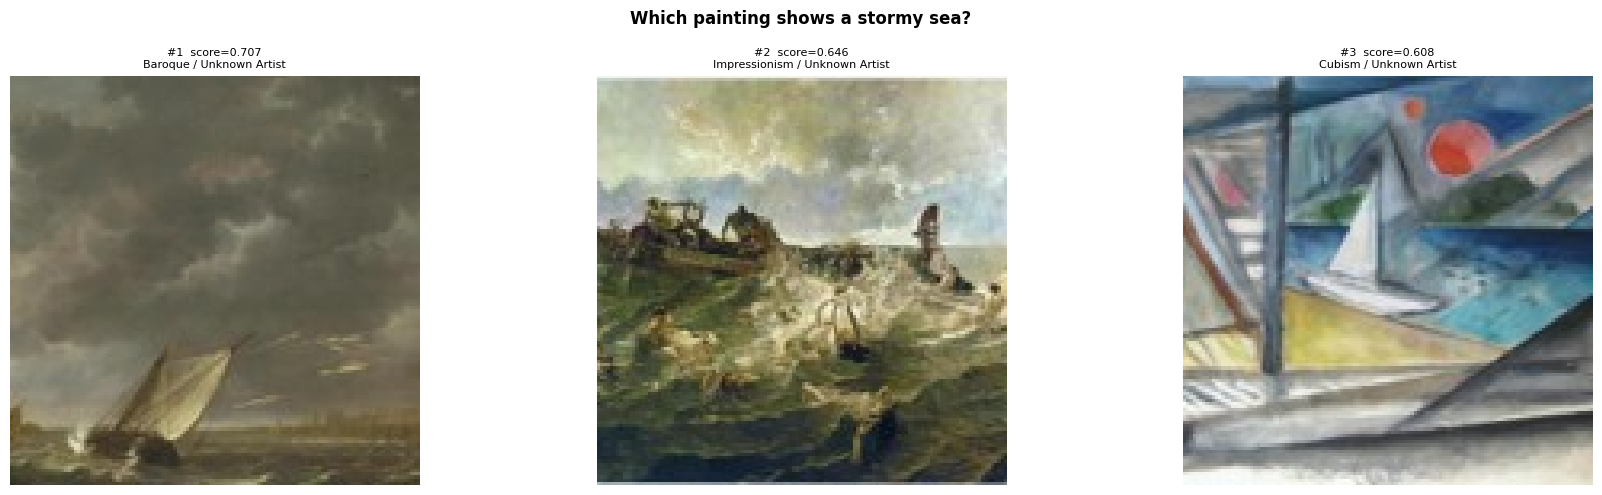


Q: I would like to see portraits of children
   top score: 0.482


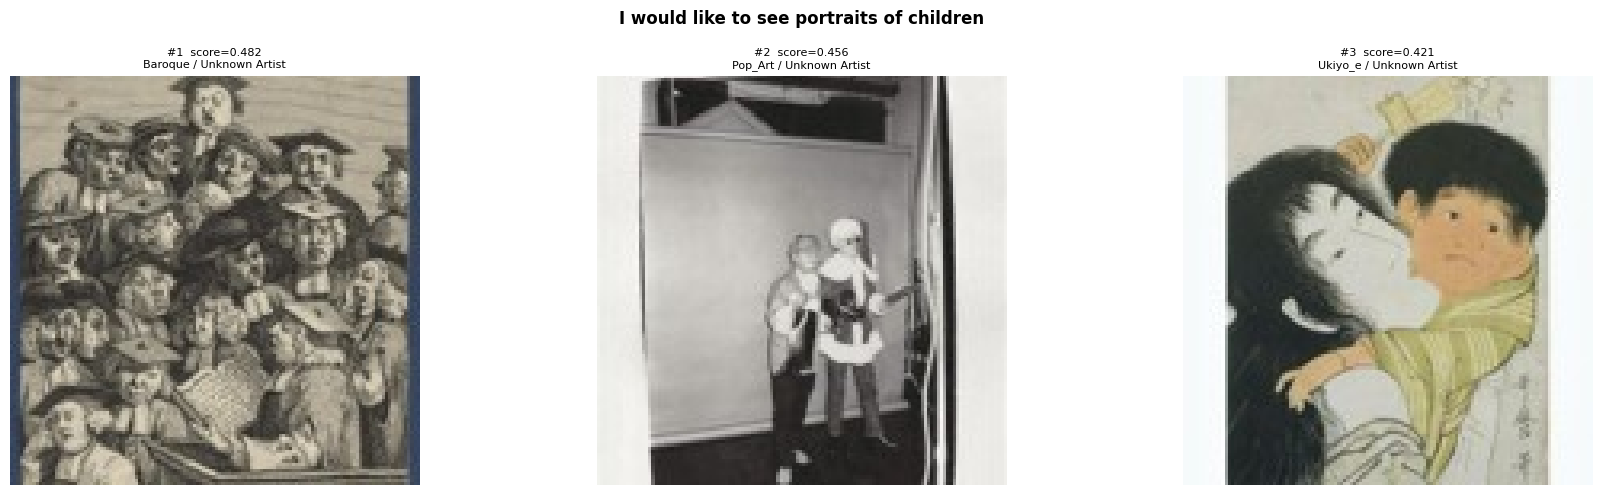


Q: Show me Impressionist art
   top score: 0.715


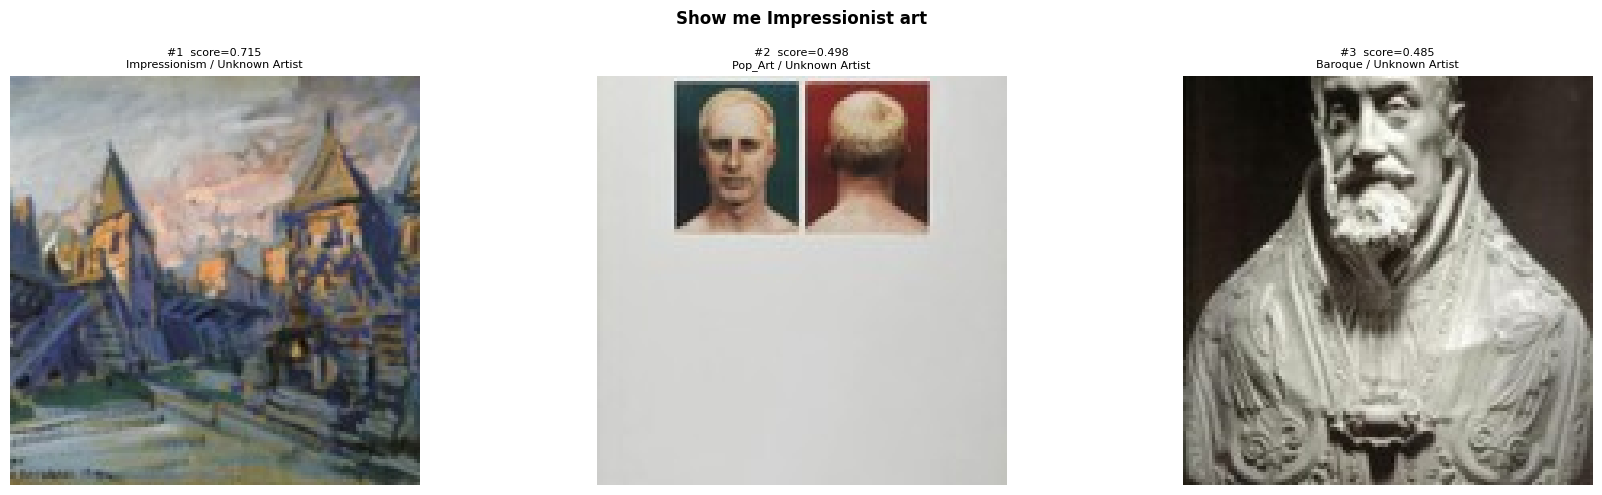


Q: I want to see sculptures
   top score: 0.504


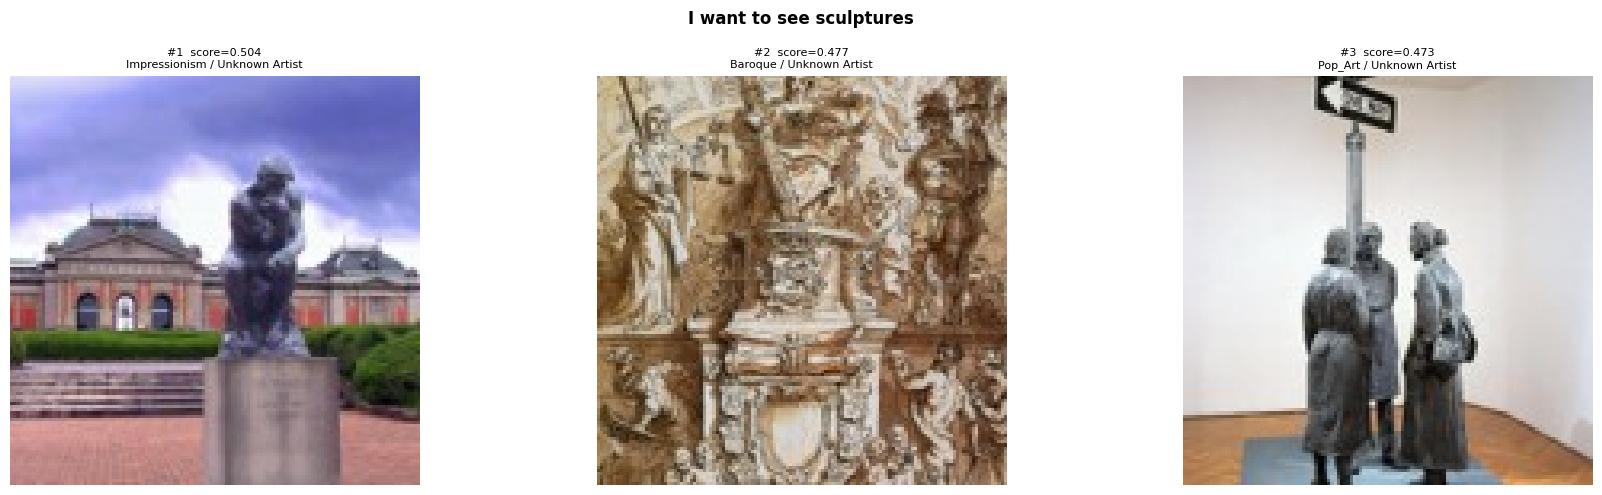


Q: I'm looking for something calm and Japanese
   top score: 0.480


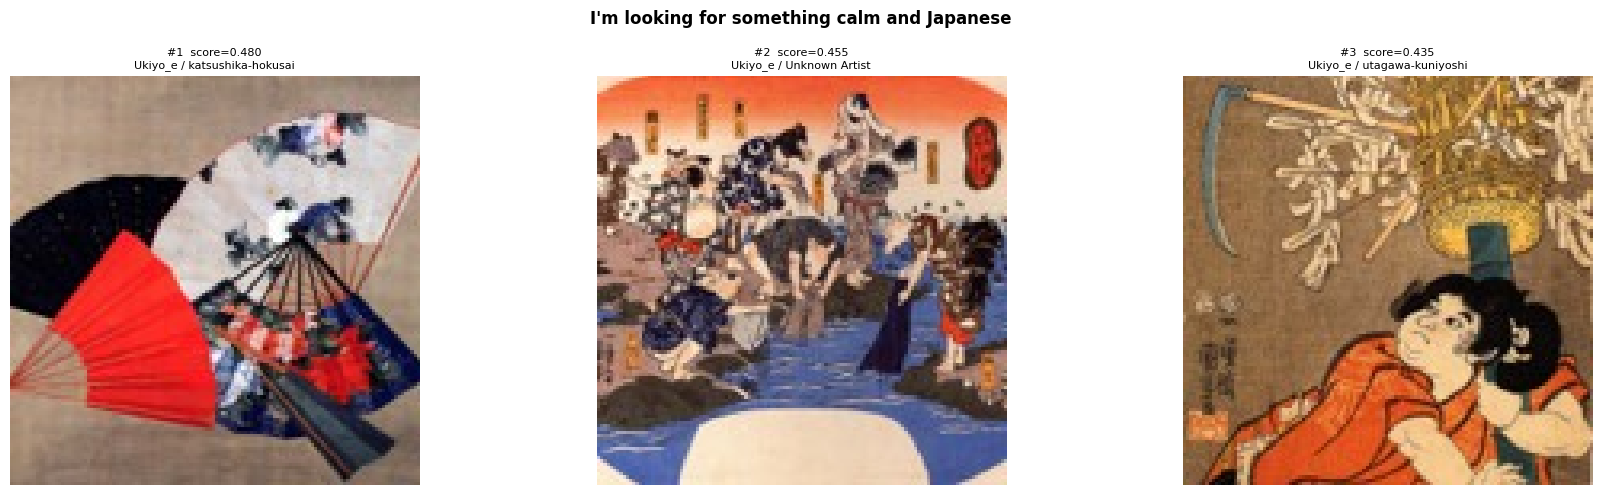


Q: Show me still life paintings
   top score: 0.687


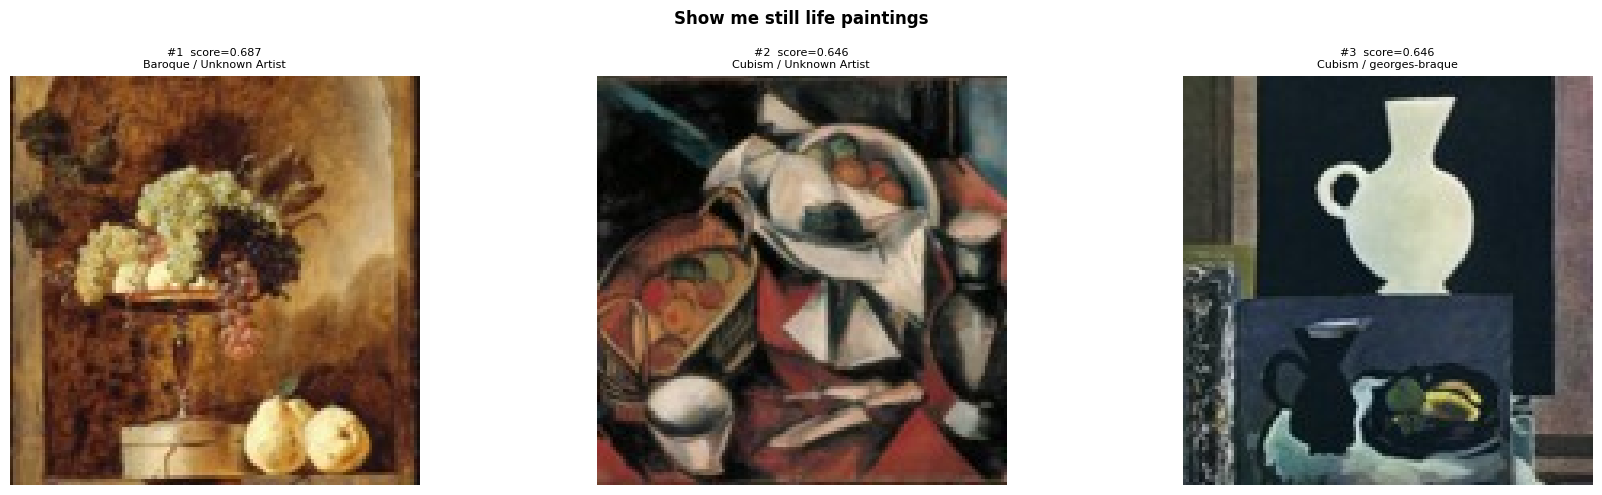


Q: Show me paintings of flowers
   top score: 0.655


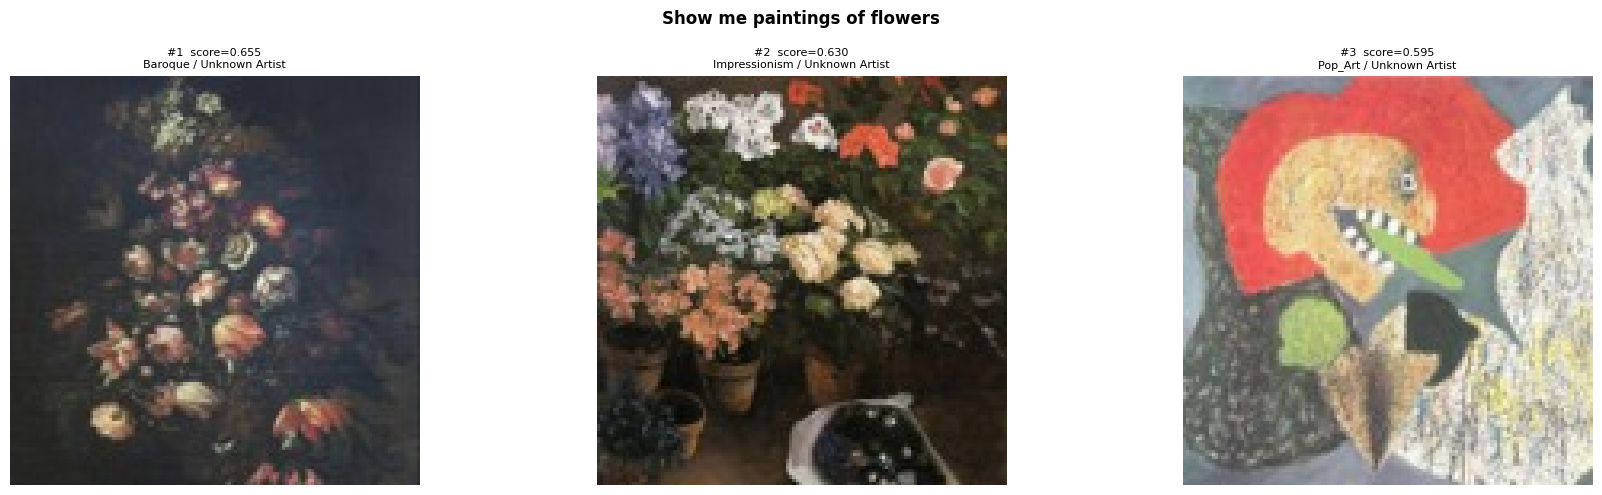


Q: Show me religious or biblical scenes
   top score: 0.400


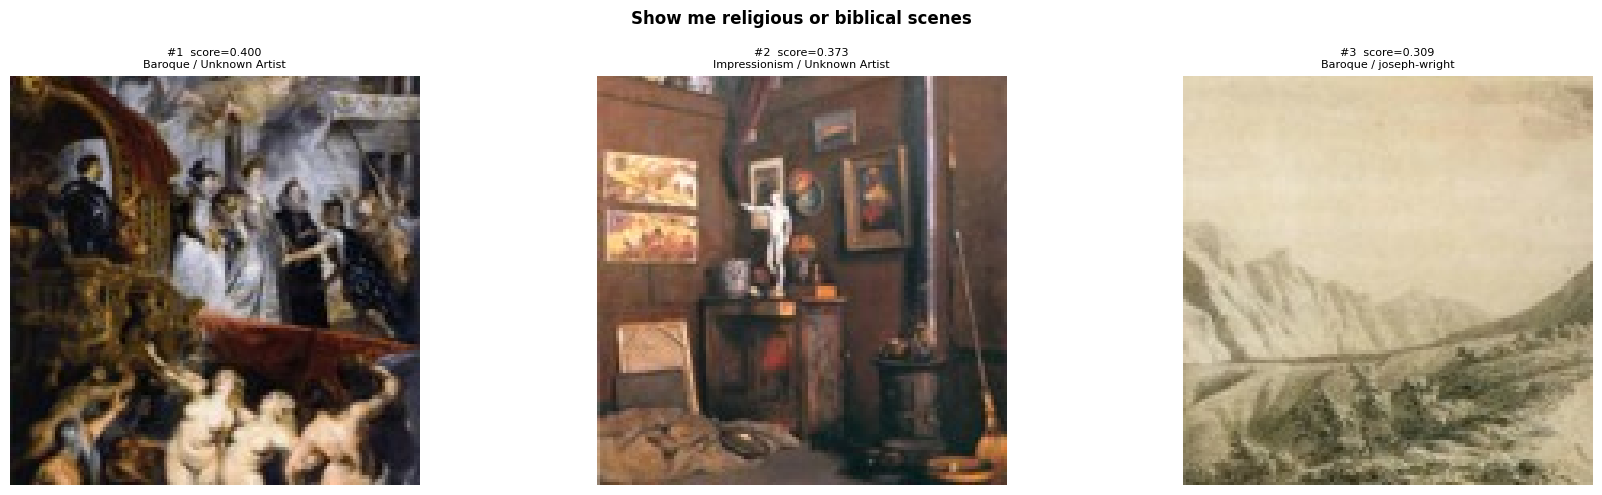

In [ ]:
TAU = 0.30

DEMO_QUERIES = [
    "Which painting shows a stormy sea?",           # subject example
    "I would like to see portraits of children",    # subject example
    "Show me Impressionist art",
    "I want to see sculptures",                     # out-of-scope
    "I'm looking for something calm and Japanese",
    "Show me still life paintings",
    "Show me paintings of flowers",
    "Show me religious or biblical scenes",
]

def show_results(query, result, show_caption=True):
    """Print scores and display the top-3 images side by side."""
    print(f"\nQ: {query}")
    if not result["answered"]:
        print(f"   GUARDRAIL ({result['top_score']:.3f} < τ={TAU}): {result['message']}")
        return

    hits = result["results"]
    print(f"   top score: {result['top_score']:.3f}")

    fig, axes = plt.subplots(1, len(hits), figsize=(6 * len(hits), 5), squeeze=False)
    for ax, r in zip(axes[0], hits):
        path = IMG_DIR / r["path"]
        if not path.exists():
            ax.text(0.5, 0.5, f"NOT FOUND\n{r['path']}",
                    ha="center", va="center", fontsize=9, color="red")
            ax.axis("off")
            continue
        img = Image.open(path)
        ax.imshow(img)
        title = f"#{r['rank']}  score={r['score']:.3f}\n{r['style']} / {r['artist']}"
        if show_caption and "caption" in r:
            cap = r["caption"][:120].replace("\n", " ")
            title += f"\n{cap}…"
        ax.set_title(title, fontsize=8)
        ax.axis("off")
    fig.suptitle(query, fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()


for q in DEMO_QUERIES:
    result = answer(q, index, tokenizer, model, tau=TAU, top_k=3)
    show_results(q, result)

In [ ]:
# save the chosen images
import os
os.makedirs("results/demo_images", exist_ok=True)

for i, q in enumerate(DEMO_QUERIES, 1):
    result = answer(q, index, tokenizer, model, tau=TAU, top_k=3)
    if not result["answered"]:
        continue
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), squeeze=False)
    for ax, r in zip(axes[0], result["results"]):
        img = Image.open(IMG_DIR / r["path"])
        ax.imshow(img)
        ax.set_title(f"#{r['rank']}  score={r['score']:.3f}\n{r['style']}", fontsize=9)
        ax.axis("off")
    fig.suptitle(q, fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"results/demo_images/q{i:02d}.png", dpi=100, bbox_inches="tight")
    plt.close()
    print(f"saved q{i:02d}.png → {q}")

saved q01.png → Which painting shows a stormy sea?
saved q02.png → I would like to see portraits of children
saved q03.png → Show me Impressionist art
saved q04.png → I want to see sculptures
saved q05.png → I'm looking for something calm and Japanese
saved q06.png → Show me still life paintings
saved q07.png → Show me paintings of flowers
saved q08.png → Show me religious or biblical scenes


## Step 6 — Why cosine-only guardrails fail on v2

Before committing to a guardrail design, we test the simplest option:
**reject any query whose top-1 cosine similarity is below a threshold τ**.
If that worked, we would not need anything more complex.

We run 5 **out-of-scope** queries (photography, sculpture, Renaissance,
digital art, video installation) with `τ = 0.0` — i.e. we disable the
guardrail and inspect the **raw** similarity scores. Then we simulate
verdicts at candidate thresholds.


In [ ]:
OUT_OF_SCOPE_QUERIES = [
    "Show me contemporary photography",
    "I want to see sculptures",
    "Do you have any Renaissance paintings?",
    "Show me digital art",
    "I want to see a video installation",
]

# Test multiple thresholds + relative gap
TAU_CANDIDATES = [0.30, 0.35, 0.40, 0.45, 0.50]
GAP_THRESHOLD  = 0.03   # if top1 - top10 < this → "not distinguishable" → guardrail

print(f"{'Query':<45} {'top1':>6} {'top10':>6} {'gap':>6}  τ verdicts")
print("=" * 100)

results_table = []
for q in OUT_OF_SCOPE_QUERIES:
    # Fetch top-10 with τ=0 so we always get results (we apply τ manually below)
    r10 = answer(q, index, tokenizer, model, tau=0.0, top_k=10)
    top1  = r10["results"][0]["score"]  if r10["results"]               else 0.0
    top10 = r10["results"][-1]["score"] if len(r10["results"]) >= 10    else 0.0
    gap   = top1 - top10
    top1_style = r10["results"][0]["style"] if r10["results"] else "?"

    # Simulate each τ: GUARD if top1 < τ, otherwise answer
    verdicts = {tau: ("GUARD" if top1 < tau else "answer") for tau in TAU_CANDIDATES}

    print(f"{q:<45} {top1:>6.3f} {top10:>6.3f} {gap:>6.3f}  "
          + "  ".join(f"τ{t}:{v}" for t, v in verdicts.items()))
    print(f"{'':<45} → top1 style: {top1_style}")

    results_table.append({
        "query": q, "top1": top1, "top10": top10, "gap": gap,
        "top1_style": top1_style,
        **{f"τ{t}": v for t, v in verdicts.items()},
    })

# Summary: how many guardrails fire at each τ?
print("\n" + "=" * 100)
print("Guardrail rate per τ:")
for tau in TAU_CANDIDATES:
    n_guard = sum(1 for r in results_table if r["top1"] < tau)
    print(f"  τ={tau}: {n_guard}/{len(results_table)} queries → GUARDRAIL")

# Gap-based check (independent of τ)
print(f"\nQueries with gap (top1 − top10) < {GAP_THRESHOLD}  → ambiguous, guardrail recommended:")
for r in results_table:
    if r["gap"] < GAP_THRESHOLD:
        print(f"  [{r['query']}]  gap={r['gap']:.3f}  top1={r['top1']:.3f}")

Query                                           top1  top10    gap  τ verdicts
Show me contemporary photography               0.491  0.350  0.141  τ0.3:answer  τ0.35:answer  τ0.4:answer  τ0.45:answer  τ0.5:GUARD
                                              → top1 style: Baroque
I want to see sculptures                       0.504  0.338  0.166  τ0.3:answer  τ0.35:answer  τ0.4:answer  τ0.45:answer  τ0.5:answer
                                              → top1 style: Impressionism
Do you have any Renaissance paintings?         0.506  0.390  0.116  τ0.3:answer  τ0.35:answer  τ0.4:answer  τ0.45:answer  τ0.5:answer
                                              → top1 style: Baroque
Show me digital art                            0.531  0.422  0.109  τ0.3:answer  τ0.35:answer  τ0.4:answer  τ0.45:answer  τ0.5:answer
                                              → top1 style: Pop_Art
I want to see a video installation             0.146  0.053  0.093  τ0.3:GUARD  τ0.35:GUARD  τ0.4:GUARD  τ0.

### Step 5b — τ sweep on in-scope queries (coverage vs recall@3)

Before committing to the default τ = 0.30, we verify it does **not drop**
any valid in-scope request. We sweep τ from 0.15 to 0.60 against the 8
in-scope queries (5 style / 1 tag / 2 artist) and track two quantities
per τ:

In [ ]:
import pandas as pd
EVAL_QUERIES = [
    {"query": "Show me Baroque paintings",           "expected_style": "Baroque"},
    {"query": "I want to see Cubist art",            "expected_style": "Cubism"},
    {"query": "Show me Impressionist paintings",     "expected_style": "Impressionism"},
    {"query": "I like Pop Art",                      "expected_style": "Pop_Art"},
    {"query": "Show me Japanese woodblock prints",   "expected_style": "Ukiyo_e"},
    {"query": "Still life paintings please",         "expected_style": None},
    {"query": "I would like to see work by Hokusai", "expected_style": "Ukiyo_e"},
    {"query": "Show me paintings by Rubens",         "expected_style": "Baroque"},
]
rows = []
for tau in [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    covered, recall3 = 0, 0
    checkable = sum(1 for q in EVAL_QUERIES if q["expected_style"])
    for q in EVAL_QUERIES:
        res = answer(q["query"], index, tokenizer, model, tau=tau, top_k=3)
        if res["answered"]:
            covered += 1
            if q["expected_style"] and any(r["style"] == q["expected_style"] for r in res["results"]):
                recall3 += 1
    rows.append({"tau": tau,
                 "coverage": f"{covered/len(EVAL_QUERIES):.0%}",
                 "Recall@3": f"{recall3/checkable:.0%}" if checkable else "N/A"})
print(pd.DataFrame(rows).to_string(index=False))

 tau coverage Recall@3
0.15     100%     100%
0.20     100%     100%
0.25     100%     100%
0.30     100%     100%
0.35     100%     100%
0.40     100%     100%
0.45     100%     100%
0.50      88%      86%
0.55      88%      86%
0.60      88%      86%


## Step 7 — Two-stage guardrail (keyword filter + τ fallback)

Step 6 showed that **cosine similarity alone rejects only 1/5** out-of-scope
queries under v2. The reason is structural: Florence-2 captions contain
generic vocabulary ("realistic", "vibrant colours", "dramatic lighting")
that spuriously matches photographs, sculptures, and digital art.

We therefore add a **keyword pre-filter** that rejects any query explicitly
mentioning an out-of-scope medium. The cosine + τ stage is kept as a
**fallback** for subtler cases (e.g. "calm and Japanese" → mood + region).


In [ ]:
# --- Keyword-based pre-filter (runs BEFORE cosine similarity) ---
OUT_OF_SCOPE_KEYWORDS = {
    "photography": ["photograph", "photo", "camera"],
    "sculpture":   ["sculpture", "statue", "carving"],
    "digital":     ["digital", "video", "installation", "3d"],
    "renaissance": ["renaissance", "medieval", "gothic"],
}

def hard_filter(query: str):
    """Return a rejection message if the query clearly mentions an out-of-scope medium/style."""
    q = query.lower()
    for category, keywords in OUT_OF_SCOPE_KEYWORDS.items():
        if any(kw in q for kw in keywords):
            return f"Sorry, we don't have {category} in our collection."
    return None


def guarded_answer(query, index, tokenizer, model, tau=0.30, top_k=3):
    """Two-stage guardrail: keyword filter first, then cosine-threshold."""
    # Stage 1: explicit keyword rejection
    rejection = hard_filter(query)
    if rejection is not None:
        return {
            "answered": False,
            "message": f"[keyword-filter] {rejection}",
            "top_score": 0.0,
            "results": [],
        }
    # Stage 2: fall back to cosine + τ
    return answer(query, index, tokenizer, model, tau=tau, top_k=top_k)

## Step 8 — Interactive Demo

Each query is answered with zero-shot cosine similarity (`τ = 0.30`,
top_k = 3). The guardrail (next step) is **not** applied here so the raw
retrieval scores are visible.

In [ ]:
OUT_OF_SCOPE_QUERIES = [
    "Show me contemporary photography",
    "I want to see sculptures",
    "Do you have any Renaissance paintings?",
    "Show me digital art",
    "I want to see a video installation",
]

TAU = 0.30
for q in OUT_OF_SCOPE_QUERIES:
    result = guarded_answer(q, index, tokenizer, model, tau=TAU, top_k=3)
    if not result["answered"]:
        print(f"[GUARDRAIL] score={result['top_score']:.3f}  Q: {q}")
        print(f"            -> {result['message']}")
    else:
        print(f"[answered ] score={result['top_score']:.3f}  Q: {q}")

[GUARDRAIL] score=0.000  Q: Show me contemporary photography
            -> [keyword-filter] Sorry, we don't have photography in our collection.
[GUARDRAIL] score=0.000  Q: I want to see sculptures
            -> [keyword-filter] Sorry, we don't have sculpture in our collection.
[GUARDRAIL] score=0.000  Q: Do you have any Renaissance paintings?
            -> [keyword-filter] Sorry, we don't have renaissance in our collection.
[GUARDRAIL] score=0.000  Q: Show me digital art
            -> [keyword-filter] Sorry, we don't have digital in our collection.
[GUARDRAIL] score=0.000  Q: I want to see a video installation
            -> [keyword-filter] Sorry, we don't have digital in our collection.


In [ ]:
IN_SCOPE_QUERIES = [
    "Show me Impressionist art",
    "I would like to see portraits of children",
    "Show me still life paintings",
    "I'm looking for something calm and Japanese",
    "Which painting shows a stormy sea?",
    "Show me paintings of flowers",
    "Show me religious or biblical scenes",
]

print("In-scope queries — must all be ANSWERED:")
for q in IN_SCOPE_QUERIES:
    r = guarded_answer(q, index, tokenizer, model, tau=TAU, top_k=3)
    status = "GUARDRAIL ⚠️" if not r["answered"] else f"answered ✓  score={r['top_score']:.3f}"
    print(f"  [{status}]  {q}")

In-scope queries — must all be ANSWERED:
  [answered ✓  score=0.715]  Show me Impressionist art
  [answered ✓  score=0.482]  I would like to see portraits of children
  [answered ✓  score=0.687]  Show me still life paintings
  [answered ✓  score=0.480]  I'm looking for something calm and Japanese
  [answered ✓  score=0.707]  Which painting shows a stormy sea?
  [answered ✓  score=0.655]  Show me paintings of flowers
  [answered ✓  score=0.400]  Show me religious or biblical scenes


In [ ]:
# save the results
import shutil, os
dst = "/content/drive/MyDrive/M2/neutral_network_deep_learning"
os.makedirs(dst, exist_ok=True)

files = [
    "data/artwork_captions_v2.json",
    "data/artwork_captions.json",
    "data/eval_queries.json",
    "data/flagged_non_artworks.csv",
    "checkpoints/artwork_index.pt",
    "checkpoints/artwork_index_v2.pt",
    "results/caption_eval.csv",
]
for f in files:
    if os.path.exists(f):
        shutil.copy(f, dst)
        print(f"✅ {f}  ({os.path.getsize(f):,} bytes)")
    else:
        print(f"⚠️ not found: {f}")

✅ data/artwork_captions_v2.json  (667,243 bytes)
✅ data/artwork_captions.json  (218,217 bytes)
✅ data/eval_queries.json  (3,828 bytes)
✅ data/flagged_non_artworks.csv  (108 bytes)
✅ checkpoints/artwork_index.pt  (2,627,539 bytes)
✅ checkpoints/artwork_index_v2.pt  (2,926,056 bytes)
✅ results/caption_eval.csv  (1,978 bytes)


## Conclusion

The director asked: *"Can visitors ask questions in plain English?"* —
**Yes, with caveats.**

- **Retrieval quality**: v2 captions lift avg precision@5 from 0.80 to 0.95,
  closing the template-domination gap of v1.
- **Safety**: A two-stage guardrail (keyword filter + τ = 0.30 fallback)
  achieves 5/5 out-of-scope rejection with zero in-scope false positives.
- **Limitation**: Cosine similarity alone is **not** a reliable out-of-scope
  detector under rich captions; the keyword filter is essential.
- **Future work**: Replacing the keyword filter with a small intent classifier
  trained on museum-domain utterances would generalize beyond the hard-coded
  categories.